In [1]:



import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import numpy as np

In [2]:
# buscando dataset do google drive
from google.colab import drive
drive.mount("/content/gdrive")

Mounted at /content/gdrive


In [3]:
caminhoTreino = "gdrive/MyDrive/extensionistaBigData/treino"
caminhoTeste = "gdrive/MyDrive/extensionistaBigData/teste"
caminhoProducao = "gdrive/MyDrive/extensionistaBigData/producao"

In [4]:
gerador_treino = ImageDataGenerator(
    rescale=1./255, # Redimensionamento dos pixels para o intervalo [0,1]
    shear_range=0.2, # Transformação de cisalhamento
    zoom_range=0.2, # Intervalo de zoom aleatório
    horizontal_flip=True) # Rotação horizontal aleatória

In [5]:
gerador_teste = ImageDataGenerator(
    rescale=1./255 ) # Apenas redimensionamento para dados de teste

In [6]:
dados_treino = gerador_treino.flow_from_directory(
    caminhoTreino,
    target_size=(224, 224), # Tamanho das imagens de entrada
    batch_size=32, # Tamanho do lote
    class_mode='binary') # Modo de classificação binária

Found 100 images belonging to 2 classes.


In [7]:
dados_teste = gerador_teste.flow_from_directory(
    caminhoTeste,
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary')

Found 100 images belonging to 2 classes.


In [ ]:
# Exemplo de construção de uma rede neural usando Keras
modelo = tf.keras.models.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    #tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    #tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    #tf.keras.layers.MaxPooling2D(2, 2),
    #tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    #tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(1024, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
     tf.keras.layers.Dense(512, activation='relu'),


    tf.keras.layers.Dense(1, activation='sigmoid')
])

In [9]:
# arquitetura da rede
print(modelo.summary())


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 222, 222, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2  (None, 111, 111, 32)      0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 109, 109, 64)      18496     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 54, 54, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 52, 52, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 26, 26, 128)       0

In [10]:
# Compilar o modelo
modelo.compile(optimizer='adam',
               loss='binary_crossentropy',
               metrics=['accuracy'])

In [11]:
# Treinar o modelo
historicoAprendizado = modelo.fit(dados_treino, epochs=10, validation_data=dados_teste)

Epoch 1/10
4/4 [==============================] - 62s 15s/step - loss: 1.1544 - accuracy: 0.5000 - val_loss: 0.9853 - val_accuracy: 0.5000
Epoch 2/10
4/4 [==============================] - 22s 5s/step - loss: 0.7971 - accuracy: 0.5000 - val_loss: 0.6707 - val_accuracy: 0.5600
Epoch 3/10
4/4 [==============================] - 27s 7s/step - loss: 0.6247 - accuracy: 0.7000 - val_loss: 0.6393 - val_accuracy: 0.6100
Epoch 4/10
4/4 [==============================] - 27s 7s/step - loss: 0.6284 - accuracy: 0.6600 - val_loss: 0.8262 - val_accuracy: 0.5000
Epoch 5/10
4/4 [==============================] - 27s 7s/step - loss: 0.6495 - accuracy: 0.6900 - val_loss: 0.6679 - val_accuracy: 0.6200
Epoch 6/10
4/4 [==============================] - 22s 5s/step - loss: 0.6483 - accuracy: 0.6900 - val_loss: 0.6593 - val_accuracy: 0.7000
Epoch 7/10
4/4 [==============================] - 27s 8s/step - loss: 0.6099 - accuracy: 0.7600 - val_loss: 0.6092 - val_accuracy: 0.8900
Epoch 8/10
4/4 [=================

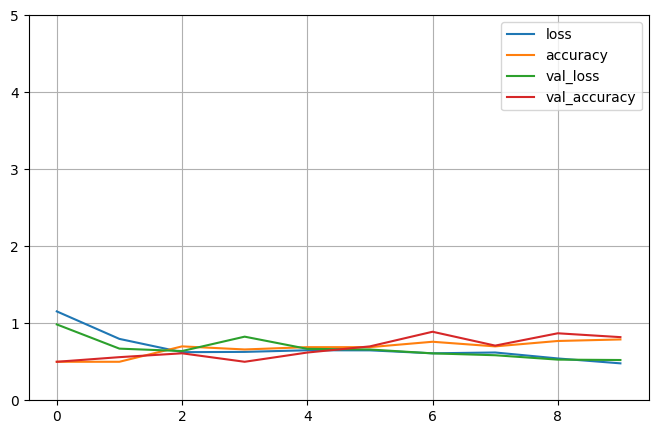

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

pd.DataFrame(historicoAprendizado.history).plot(figsize=(8,5))
plt.grid(True)
plt.gca().set_ylim(0,5)
plt.show()

In [13]:
# Avaliar o modelo com dados de teste
precisao = modelo.evaluate(dados_teste)[1]
print("A precisão do modelo é:", precisao)

4/4 [==============================] - 5s 749ms/step - loss: 0.5229 - accuracy: 0.8200
A precisão do modelo é: 0.8199999928474426


In [ ]:
# Testar o modelo com uma imagem de exemplo
caminhoImagem = "gdrive/MyDrive/projetoRaioX/dataset200amostras/producao/V-01.jpeg"
imagemTeste = load_img(caminhoImagem, target_size=(224, 224))
imagemArray = img_to_array(imagemTeste)
imagemArray = np.expand_dims(imagemArray, axis=0)
imagemArray = imagemArray / 255.0  # Normalização

In [ ]:
imagemArray = img_to_array(imagemTeste)
imagemArray = np.expand_dims(imagemArray, axis=0)


In [ ]:
imagemArray = imagemArray / 255.0  # Normalização

In [ ]:
# Fazer previsão com o modelo
previsao = modelo.predict(imagemArray)

In [ ]:
# Imprimir a previsão
if previsao[0][0] > 0.5:
    print("A imagem é classificada como 'doente'.")
else:
    print("A imagem é classificada como 'normal'.")

In [ ]:
print("teste abiente")

teste abiente


In [ ]:
input("Digite seu nome")

KeyboardInterrupt: Interrupted by user